# Salario medio anual en términos reales

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "salario-medio-real"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario medio anual en términos reales"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Dólares PPA a precios constantes de 2025"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El salario bruto medio anual por asalariado equivalente a tiempo completo, descontada la inflación y en dólares con la misma capacidad de compra en todos los países (paridad de poder adquisitivo, PPA).

**Cómo se lee.** La OCDE divide la masa salarial de la contabilidad nacional entre el número de asalariados equivalentes a tiempo completo y lo multiplica por el cociente entre las horas medias semanales de un asalariado a tiempo completo y las de todos los asalariados. Es un salario **medio**: lo mueven también los salarios más altos, y no es el salario de una persona típica (el mediano).

**Limitaciones.**
- Es bruto: no descuenta impuestos ni cotizaciones del trabajador.
- Los cambios en la composición del empleo (más o menos empleos de salario bajo) mueven la media aunque no cambien los salarios de nadie.
- La OCDE publica la serie desde 1990 y no publica el agregado de la UE-27.

## 2. Descarga

- **España, EE. UU., Canadá y OCDE:** OCDE, *Average annual wages* (`OECD.ELS.SAE,DSD_EARNINGS@AV_AN_WAGE`, versión 1.0): salario medio anual (`WG`, `MEAN`) en dólares PPA (`USD_PPP`) a precios constantes (`Q`), con el año de referencia de la última edición (`BASE_PER`, comprobado en el código).
- **UE-27:** sin dato; la OCDE no publica el agregado en este dataflow y Eurostat no tiene un indicador equivalente en PPA a precios constantes.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
from datetime import date

import requests

from lib._http import pedir
from lib import eurostat, oecd
from lib.tipos import FuenteMeta

HOY = date.today().isoformat()

AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde", "EU27_2020": "ue27"}
DATAFLOW = "OECD.ELS.SAE,DSD_EARNINGS@AV_AN_WAGE,1.0"
# Dimensiones: país . medida . unidad . periodo de pago . precios (Q: constantes) . operación . sexo
CLAVE = "{AREA}.WG.USD_PPP.A.Q.MEAN._Z"

oc, fuentes_oc = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))


def metadatos(dataflow, clave, areas):
    """SDMX-CSV completo de la OCDE (con BASE_PER y OBS_STATUS), que `oecd.get` no devuelve."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{dataflow}/{clave.replace('{AREA}', '+'.join(areas))}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="metadatos", mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


meta = metadatos(DATAFLOW, CLAVE, AREAS)
ANIO_BASE = sorted(meta["BASE_PER"].dropna().unique())
print("Año de referencia de los precios constantes:", ANIO_BASE)

         min   max  count
serie                    
canada  1990  2025     36
eeuu    1990  2025     36
espana  1990  2025     36
ocde    1990  2025     36


Año de referencia de los precios constantes: ['2025']


## 3. Transformación

1. La serie se usa tal como la publica la OCDE (ya está deflactada y en PPA). Se comprueba que el año de referencia es el que dice `UNIDAD`.
2. La UE-27 queda sin dato, con la fuente consultada.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


assert ANIO_BASE == ["2025"], "El año de referencia ya no es 2025: actualiza UNIDAD y las notas"
SIN = (oecd.ORGANISMO, "DSD_EARNINGS@AV_AN_WAGE: la OCDE no publica el agregado de la UE-27", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(oc, fuentes_oc, {s: SIN for s in ["ue27"] if s not in set(oc["serie"])})
ULTIMO = int(oc["periodo"].max())
NOTAS = [
    "OCDE, salarios medios anuales (DSD_EARNINGS@AV_AN_WAGE): masa salarial de la contabilidad nacional dividida entre "
    "los asalariados equivalentes a tiempo completo, en dólares PPA a precios constantes de "
    f"{ANIO_BASE[0]} (deflactor del consumo privado y PPA del consumo privado de {ANIO_BASE[0]}).",
    "Es el salario bruto medio, no el mediano: lo mueven los cambios en la composición del empleo y los salarios más altos.",
    "UE-27: la OCDE no publica el agregado en este indicador y la serie queda vacía.",
    f"Datos de {int(oc['periodo'].min())} a {ULTIMO}; la OCDE publica la serie desde 1990.",
]
for n in NOTAS:
    print("-", n)
display(df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").tail(6).round(0))

- OCDE, salarios medios anuales (DSD_EARNINGS@AV_AN_WAGE): masa salarial de la contabilidad nacional dividida entre los asalariados equivalentes a tiempo completo, en dólares PPA a precios constantes de 2025 (deflactor del consumo privado y PPA del consumo privado de 2025).
- Es el salario bruto medio, no el mediano: lo mueven los cambios en la composición del empleo y los salarios más altos.
- UE-27: la OCDE no publica el agregado en este indicador y la serie queda vacía.
- Datos de 1990 a 2025; la OCDE publica la serie desde 1990.


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2020,68086.0,85171.0,55380.0,62940.0,NaN
2021,68434.0,86696.0,57625.0,63799.0,NaN
2022,67334.0,84215.0,56683.0,62365.0,NaN
2023,67036.0,83866.0,56286.0,62523.0,NaN
2024,67768.0,85546.0,57083.0,64040.0,NaN
2025,67901.0,86977.0,57779.0,64803.0,NaN


## 4. Visualización

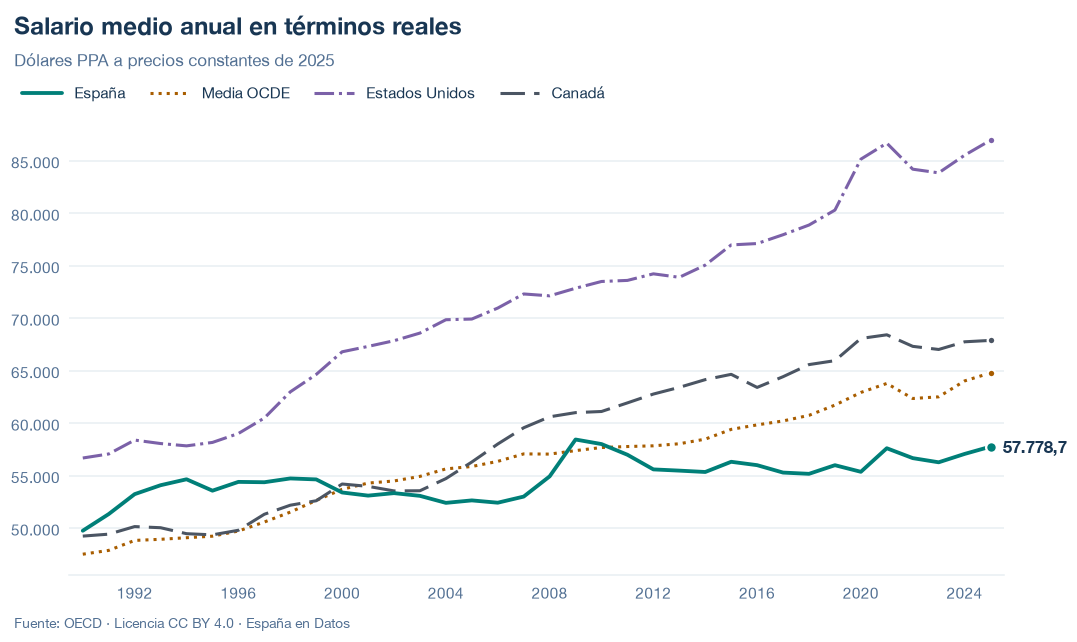

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/salario-medio-real.json y data/salario-medio-real.csv


## 6. Fuentes, notas y licencia

- OCDE, salarios medios anuales: `OECD.ELS.SAE,DSD_EARNINGS@AV_AN_WAGE,1.0` (`WG`, `USD_PPP`, `A`, `Q`, `MEAN`, `_Z`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.